https://github.com/WilsonTunggala1/Technical_Test

# Import Library that Used

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline

from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Read the Data

Data when extracted from the source is in .dat format so I will change it into csv and place it inside data/

The data is tab-delimited

In [2]:
columns = [
    "frequency_hz",
    "angle_of_attack_deg",
    "chord_length_m",
    "free_stream_velocity_m_per_s",
    "suction_side_displacement_thickness_m",
    "scaled_sound_pressure_level_db"
]
data = pd.read_csv("data/airfoil_self_noise.dat", delimiter="\t", header=None, names=columns)  # change delimiter as needed
data.to_csv("data/q1_airfoil_self_noise.csv", index=False)


In [3]:
df = pd.read_csv("data/q1_airfoil_self_noise.csv")
df.head()

,frequency_hz,angle_of_attack_deg,chord_length_m,free_stream_velocity_m_per_s,suction_side_displacement_thickness_m,scaled_sound_pressure_level_db
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


| Column | Unit | Meaning |
|---|---|---|
| frequency_hz | Hz | Centre frequency of the measured band; the rows of one test form a spectrum. |
| angle_of_attack_deg | deg | Angle between the airfoil and the oncoming air. |
| chord_length_m | m | Airfoil length from leading to trailing edge. |
| free_stream_velocity_m_per_s | m/s | Wind-tunnel air speed. |
| suction_side_displacement_thickness_m | m | Thickness of the slowed-down air layer on the upper surface. |
| **scaled_sound_pressure_level_db** | dB | **Target. Noise level, log scale.** |

From this table, these are my assumption for each variable

1. angle_of_attack_deg (Included): We assume the engineering team chooses this angle before the test. It is the tilt of the blade against the oncoming air.

2. chord_length_m (Included): We assume the team knows this length before the test. It is the width of the blade from the front edge to the back edge.

3. free_stream_velocity_m_per_s (Included): We assume the team sets this air speed before the test. It is how fast the air moves in the wind tunnel.

4. frequency_hz (Included): We assume the team selects these sound frequencies when using the model. For each blade setup, the team wants to predict noise across standard sound pitches (for example, from 200 Hz to 20,000 Hz).

5. suction_side_displacement_thickness_m (Excluded): We assume the team does not know this value before a test. This value measures the thin layer of slow air on the top surface of the blade. To find it without a wind tunnel, engineers must run slow computer simulations. Because we want a fast screening tool that only uses basic blade settings, we remove this input from model to train.

6. scaled_sound_pressure_level_db (Target): We assume the wind tunnel sensors measured this noise level accurately. We also assume all tests used the exact same blade shape (NACA 0012), blade width, and microphone position, with very little measurement error.

# Preprocessing

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1503 entries, 0 to 1502
Data columns (total 6 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   frequency_hz                           1503 non-null   int64  
 1   angle_of_attack_deg                    1503 non-null   float64
 2   chord_length_m                         1503 non-null   float64
 3   free_stream_velocity_m_per_s           1503 non-null   float64
 4   suction_side_displacement_thickness_m  1503 non-null   float64
 5   scaled_sound_pressure_level_db         1503 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 70.6 KB


From here we can see that there is no missing value from the data.

Total rows : 1503
Total columns: 6

In [5]:
print(df.duplicated().sum())

0


There is no duplicate in data

In [6]:
df.describe()

,frequency_hz,angle_of_attack_deg,chord_length_m,free_stream_velocity_m_per_s,suction_side_displacement_thickness_m,scaled_sound_pressure_level_db
count,1503.000000,1503.000000,1503.000000,1503.000000,1503.000000,1503.000000
mean,2886.380572,6.782302,0.136548,50.860745,0.011140,124.835943
std,3152.573137,5.918128,0.093541,15.572784,0.013150,6.898657
min,200.000000,0.000000,0.025400,31.700000,0.000401,103.380000
25%,800.000000,2.000000,0.050800,39.600000,0.002535,120.191000
50%,1600.000000,5.400000,0.101600,39.600000,0.004957,125.721000
75%,4000.000000,9.900000,0.228600,71.300000,0.015576,129.995500
max,20000.000000,22.200000,0.304800,71.300000,0.058411,140.987000


In [7]:
# Check how many unique wind-tunnel configurations exist for splitting the dataset
config_cols = [
    "angle_of_attack_deg",
    "chord_length_m",
    "free_stream_velocity_m_per_s",
]
df["config_id"] = df.groupby(config_cols).ngroup()
print(f"Unique wind-tunnel configurations: {df['config_id'].nunique()}")
print(
    "Rows (frequencies) per configuration (min / median / max):",
    df.groupby("config_id").size().min(),
    "/",
    df.groupby("config_id").size().median(),
    "/",
    df.groupby("config_id").size().max(),
)

Unique wind-tunnel configurations: 106
Rows (frequencies) per configuration (min / median / max): 8 / 14.0 / 19


In this dataset, each physical wind-tunnel setup is defined by a unique combination of angle of attack, chord length, and air speed. Each setup was tested across 10 to 16 different sound frequencies, resulting in multiple rows sharing the same config_id. Instead of splitting individual rows randomly, we grouped the data by config_id so that all frequency measurements for a given blade setup stay together in either the training set or the testing set. This prevents the model from memorizing nearby frequency points from the same blade setup and ensures our evaluation reflects how well the model predicts noise for completely new, unseen blade designs.

In [8]:
df = df.drop(columns=["suction_side_displacement_thickness_m"])

We dropped the suction_side_displacement_thickness column from our inputs because it is a physical airflow measurement recorded inside the wind tunnel during testing. As stated in variable assumptions, engineers do not have this measurement available during early-stage blade design when they only know basic geometry and speed settings. Keeping this feature would cause data leakage, making the model appear artificially accurate during training while failing in real-world screening.

In [9]:
# Split the Data using GroupShuffleSplit
# Group-aware train/test split (80% train configs, 20% test configs)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(df, groups=df["config_id"]))
train = df.iloc[train_idx].copy()
test = df.iloc[test_idx].copy()

In [10]:
# Verify zero configuration overlap between train and test
overlap = set(train["config_id"]).intersection(set(test["config_id"]))
print(f"\nTrain shape: {train.shape} ({train['config_id'].nunique()} configs)")
print(f"Test shape:  {test.shape} ({test['config_id'].nunique()} configs)")
print(f"Overlapping configurations between train and test: {len(overlap)}")


Train shape: (1182, 6) (84 configs)
Test shape:  (321, 6) (22 configs)
Overlapping configurations between train and test: 0


The dataset was split by blade configuration (config_id) into a training set of 1,182 rows across 84 configurations (about 79% of the data) and a testing set of 321 rows across 22 configurations (about 21% of the data), with 0 overlapping configurations between the two sets. 

Both sets contain 6 columns: frequency_hz, angle_of_attack_deg, chord_length_m, free_stream_velocity_m_per_s, scaled_sound_pressure_level_db, and config_id. 

Having zero shared configurations ensures that the test set evaluates the model on completely unseen wind-tunnel setups, preventing data leakage and matching how engineers will screen new blade designs.

# EDA

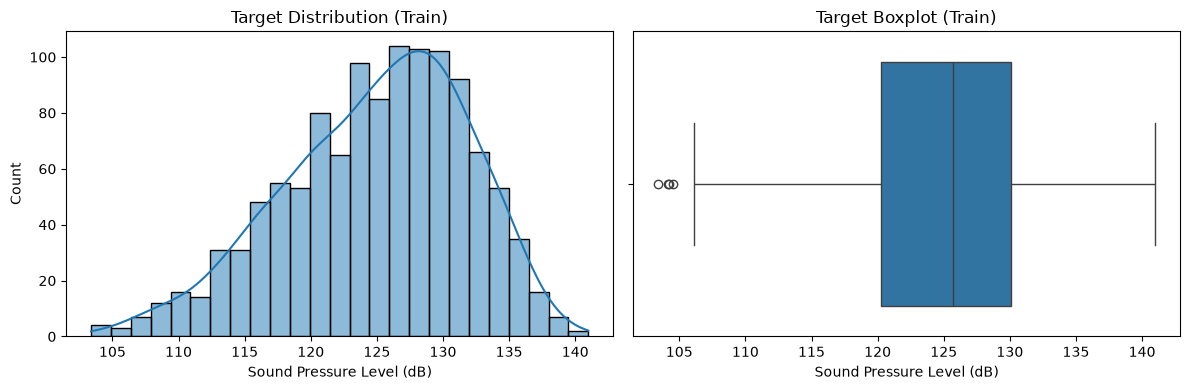

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram + KDE curve
sns.histplot(
    train["scaled_sound_pressure_level_db"], kde=True, bins=25, ax=axes[0]
)
axes[0].set_title("Target Distribution (Train)")
axes[0].set_xlabel("Sound Pressure Level (dB)")
axes[0].set_ylabel("Count")

# Boxplot to check spread and outliers
sns.boxplot(x=train["scaled_sound_pressure_level_db"], ax=axes[1])
axes[1].set_title("Target Boxplot (Train)")
axes[1].set_xlabel("Sound Pressure Level (dB)")

plt.tight_layout()
plt.show()

The sound levels in the training set range from about 103 dB to 140 dB.

Most target have noise levels between 120 dB and 130 dB. The middle value (median) is around 126 dB, and the most common peak is near 128 dB. 

The histogram shows a mostly bell-shaped curve with slightly left-skewed.  

The boxplot shows a few small dots below 106 dB. These are valid quiet measurements (usually from very high sound frequencies), so we keep them in the data rather than removing them.   

Because the noise levels are already well-behaved and do not have extreme spikes, we do not need to apply a log transformation or any special scaling to the target variable.

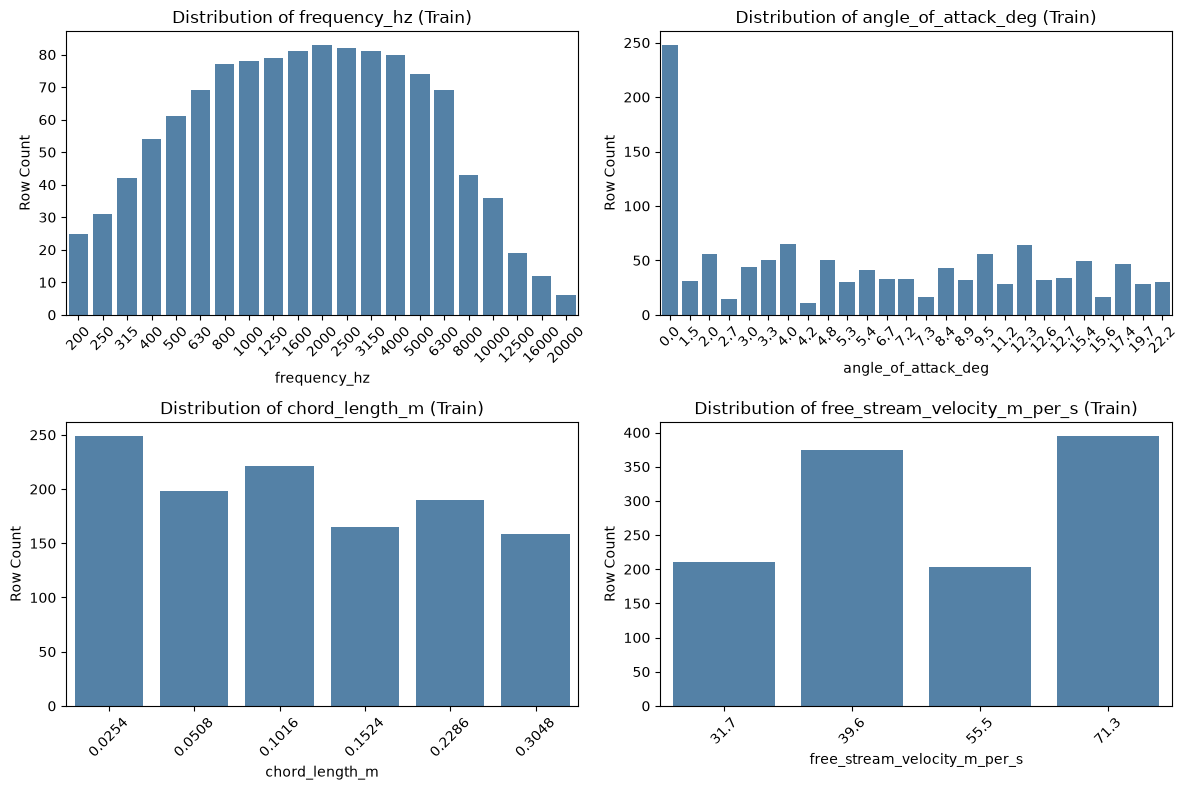

In [12]:
features = [
    "frequency_hz",
    "angle_of_attack_deg",
    "chord_length_m",
    "free_stream_velocity_m_per_s",
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(features):
    # Countplot shows exact discrete test values clearly
    sns.countplot(x=train[col], ax=axes[i], color="steelblue")
    axes[i].set_title(f"Distribution of {col} (Train)")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Row Count")
    axes[i].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

frequency_hz (Top Left): Most measurements were recorded in the middle sound range between 800 Hz and 6,300 Hz (about 70 to 83 rows per band). Very low pitches (200 Hz) and very high pitches (above 10,000 Hz) have far fewer measurements.  

angle_of_attack_deg (Top Right): A flat angle of 0.0 degrees has the most data by far (nearly 250 rows). All other tilted angles up to 22.2 degrees have much smaller, uneven counts (between 10 and 65 rows each).  

chord_length_m (Bottom Left): Only 6 specific blade lengths were tested, ranging from 0.0254 m (1 inch) to 0.3048 m (12 inches). The row counts are fairly balanced across all six lengths (between 160 and 250 rows each).

free_stream_velocity_m_per_s (Bottom Right): Only 4 specific air speeds were tested (31.7, 39.6, 55.5, and 71.3 m/s). Speeds of 39.6 m/s and 71.3 m/s have almost twice as many measurements as the other two speeds.

Constraint for modelling: Because the model only sees 6 blade lengths and 4 air speeds during training, it will be most accurate near those exact values and less reliable if asked to predict outside this range.

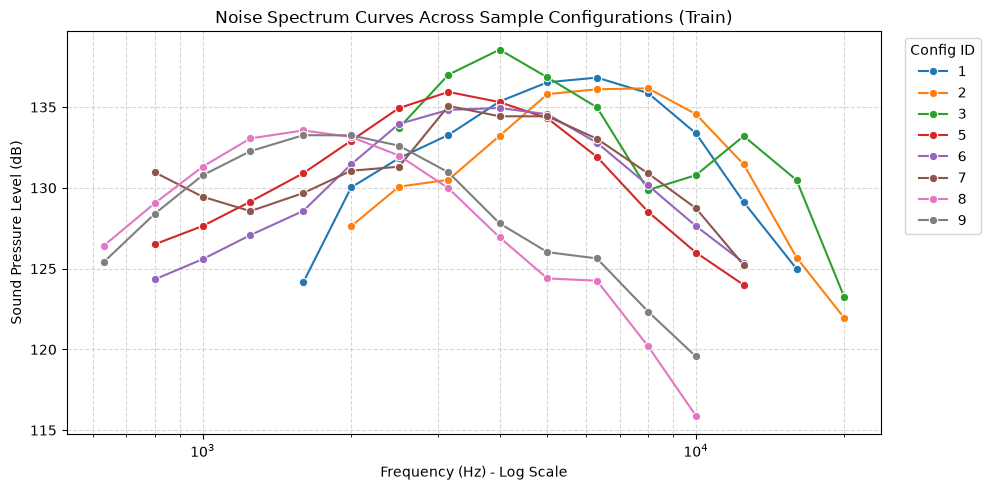

In [13]:
# Pick 8 sample configurations from train to keep the plot clean
sample_ids = sorted(train["config_id"].unique())[:8]
sample_df = train[train["config_id"].isin(sample_ids)].sort_values(
    "frequency_hz"
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=sample_df,
    x="frequency_hz",
    y="scaled_sound_pressure_level_db",
    hue="config_id",
    marker="o",
    palette="tab10",
)

# Use log scale for frequency because sound bands grow exponentially
plt.xscale("log")
plt.title("Noise Spectrum Curves Across Sample Configurations (Train)")
plt.xlabel("Frequency (Hz) - Log Scale")
plt.ylabel("Sound Pressure Level (dB)")
plt.legend(title="Config ID", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Why Only 8 Samples? The training set has about 84 different blade setups. Plotting all 84 lines at once creates a messy web where nothing is readable. Showing just 8 setups makes the smooth curve shape easy to see. (Config ID 4 is missing from the plot because it was in the test data).

Why Use LogScale? On a normal linear x-axis, all the dots between 200 Hz and 2,000 Hz get squished tightly together on the far left edge, while 10,000 Hz to 20,000 Hz takes up half the chart. Using a log scale spaces the dots out evenly so we can clearly see the curve at low and middle pitches.

Each colored line shows the sound pattern for one blade setup (Config ID) from the training set. As sound pitch (frequency_hz) goes up, the noise level rises, hits a peak in the middle frequencies (around 1,500 Hz to 6,300 Hz), and then drops at very high frequencies.   

For modelling: Because the lines curve up and down, even show small secondary bumps (like Config 3 near 12,500 Hz). A simple straight-line model cannot fit this data. I need non-linear model (like a tree-based model) that can learn curves.

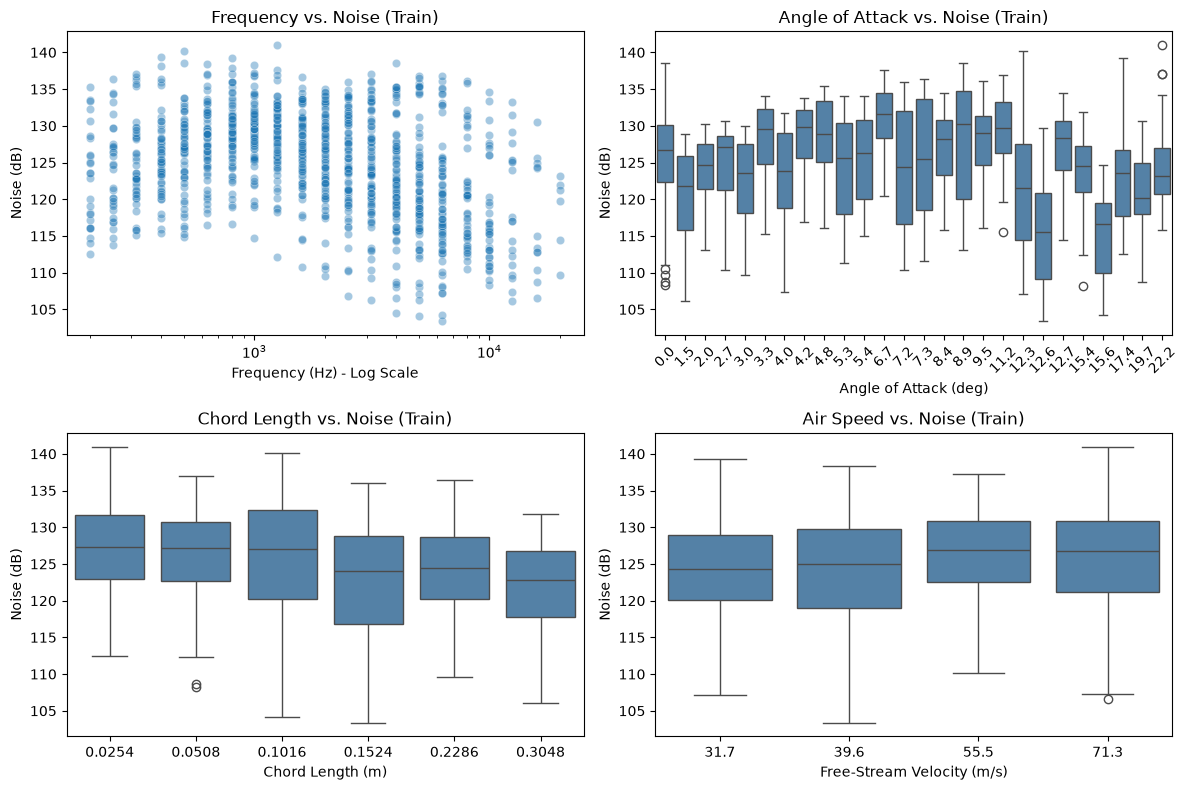

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Frequency vs Noise (log scale on x-axis)
sns.scatterplot(
    data=train,
    x="frequency_hz",
    y="scaled_sound_pressure_level_db",
    alpha=0.4,
    ax=axes[0, 0],
)
axes[0, 0].set_xscale("log")
axes[0, 0].set_title("Frequency vs. Noise (Train)")
axes[0, 0].set_xlabel("Frequency (Hz) - Log Scale")
axes[0, 0].set_ylabel("Noise (dB)")

# Angle of Attack vs Noise
sns.boxplot(
    data=train,
    x="angle_of_attack_deg",
    y="scaled_sound_pressure_level_db",
    ax=axes[0, 1],
    color="steelblue",
)
axes[0, 1].set_title("Angle of Attack vs. Noise (Train)")
axes[0, 1].set_xlabel("Angle of Attack (deg)")
axes[0, 1].set_ylabel("Noise (dB)")
axes[0, 1].tick_params(axis="x", rotation=45)

# Chord Length vs Noise
sns.boxplot(
    data=train,
    x="chord_length_m",
    y="scaled_sound_pressure_level_db",
    ax=axes[1, 0],
    color="steelblue",
)
axes[1, 0].set_title("Chord Length vs. Noise (Train)")
axes[1, 0].set_xlabel("Chord Length (m)")
axes[1, 0].set_ylabel("Noise (dB)")

# Free-Stream Velocity vs Noise
sns.boxplot(
    data=train,
    x="free_stream_velocity_m_per_s",
    y="scaled_sound_pressure_level_db",
    ax=axes[1, 1],
    color="steelblue",
)
axes[1, 1].set_title("Air Speed vs. Noise (Train)")
axes[1, 1].set_xlabel("Free-Stream Velocity (m/s)")
axes[1, 1].set_ylabel("Noise (dB)")

plt.tight_layout()
plt.show()

Frequency vs. Noise (Top Left): Noise stays mostly between 115 dB and 135 dB at low and middle sound pitches. Above 2,000 Hz, the minimum noise drops sharply down toward 103 dB, showing that very high-pitched sounds are often much quieter.

Angle of Attack vs. Noise (Top Right): Changing the blade tilt does not follow a simple straight-line rule. Middle angles (around 6.7° to 11.2°) have higher typical noise (medians near 130 dB), while steeper angles like 12.6° and 15.6° show much lower median noise (around 115–116 dB).   

Chord Length vs. Noise (Bottom Left): Shorter blades (0.0254 m to 0.1016 m) tend to produce slightly higher median noise (around 127 dB). As the blade gets wider up to 0.3048 m, the median noise drops gently down to about 123 dB.   

Air Speed vs. Noise (Bottom Right): Faster air speed pushes noise slightly upward. The median noise rises from about 124 dB at 31.7 m/s to nearly 127 dB at 55.5 m/s and 71.3 m/s, with the loudest single reading (above 140 dB) happening at the highest speed.  

For modelling: No single input explains noise on its own. This proves that noise depends on the combined interaction of all four settings together, so we need models that capture feature interactions (such as tree ensembles).   

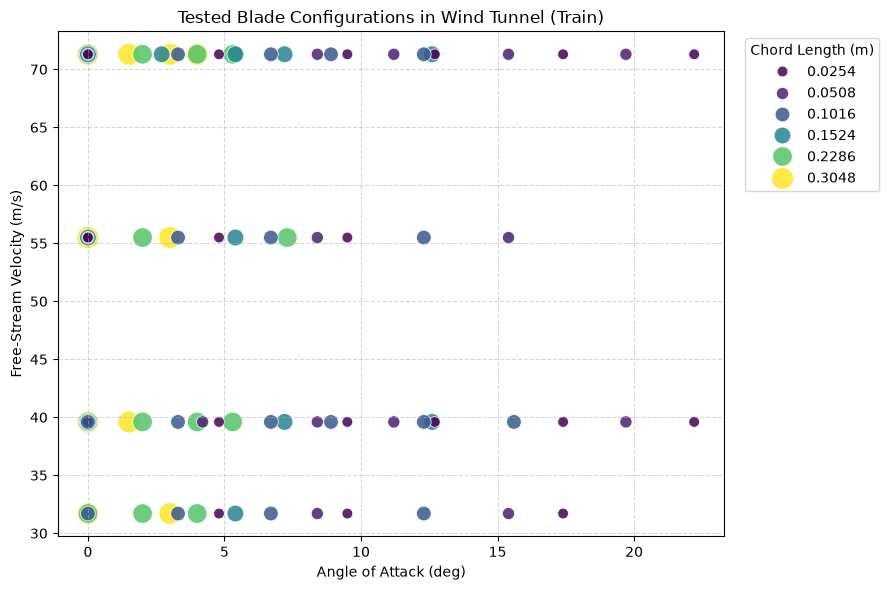

In [15]:
configs_train = train[
    [
        "config_id",
        "angle_of_attack_deg",
        "chord_length_m",
        "free_stream_velocity_m_per_s",
    ]
].drop_duplicates()

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=configs_train,
    x="angle_of_attack_deg",
    y="free_stream_velocity_m_per_s",
    hue="chord_length_m",
    size="chord_length_m",
    sizes=(60, 250),
    palette="viridis",
    alpha=0.85,
)

plt.title("Tested Blade Configurations in Wind Tunnel (Train)")
plt.xlabel("Angle of Attack (deg)")
plt.ylabel("Free-Stream Velocity (m/s)")
plt.legend(title="Chord Length (m)", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

The wind tunnel only ran at 4 fixed air speeds (31.7, 39.6, 55.5, and 71.3 m/s), with large empty gaps between them.   

At an angle of 0.0 degrees, all six blade sizes (from small purple dots to large yellow dots) were tested across all four air speeds.

The largest blades (0.2286 m in green and 0.3048 m in yellow) were only tested at gentle angles up to about 7.3 degrees. None of the large blades were tested at steep angles.  

Steep angles above 15 degrees only have tiny dark purple dots (0.0254 m and 0.0508 m blades). Also, the steepest angles (around 19.7° and 22.2°) were only tested at two air speeds (39.6 and 71.3 m/s), leaving empty white space at 31.7 and 55.5 m/s.   

When Not to Trust the Model: The empty white regions on this map are blind spots. We should not trust the model if an engineer asks about a large blade at a steep angle (for example, 0.3048 m at 15 degrees), or an air speed far outside 31.7 to 71.3 m/s.

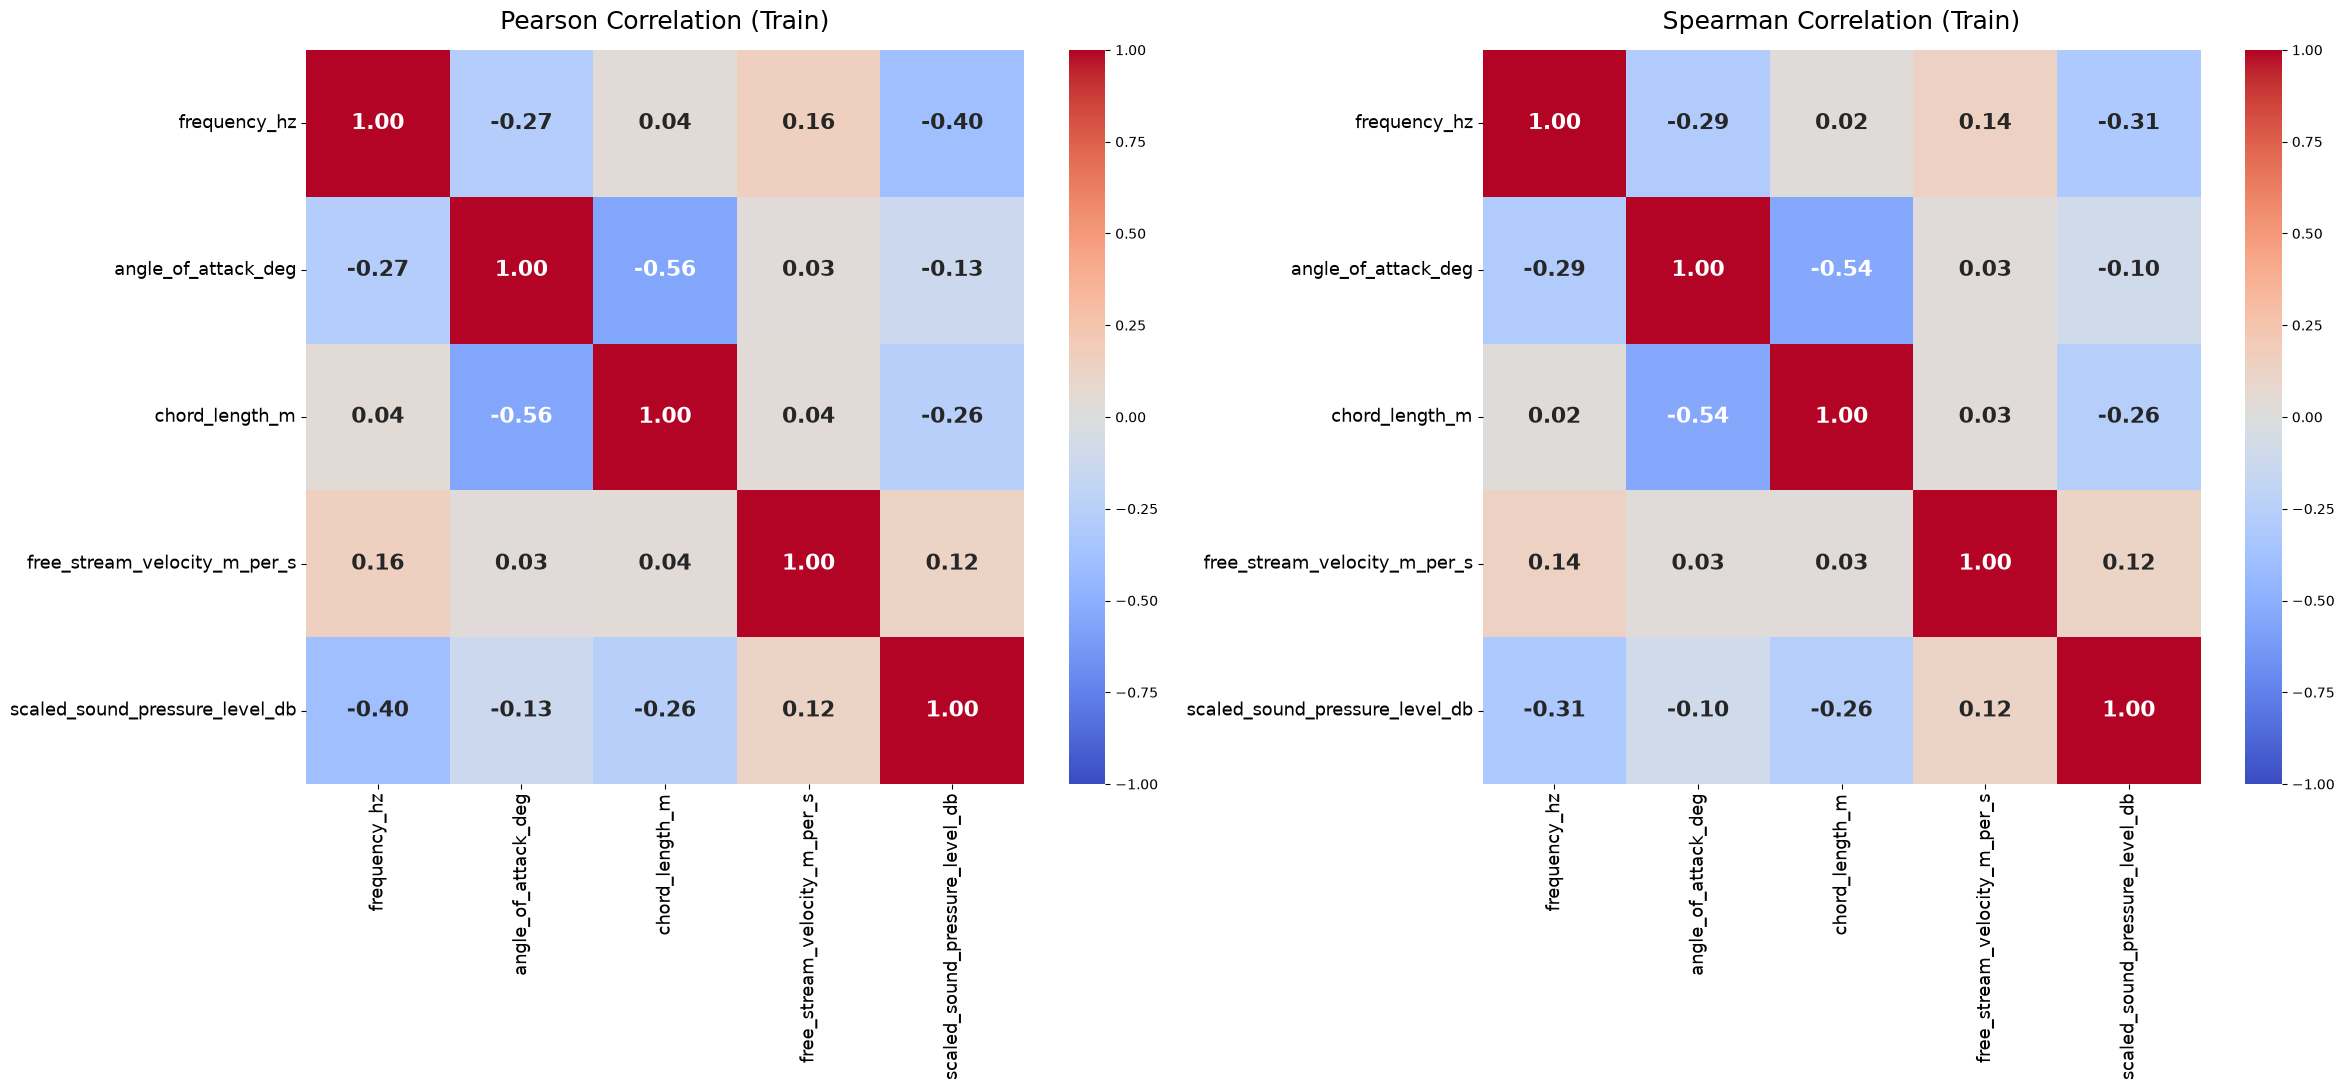

In [16]:
# Select only the 4 model input features and the target variable
cols = [
    "frequency_hz",
    "angle_of_attack_deg",
    "chord_length_m",
    "free_stream_velocity_m_per_s",
    "scaled_sound_pressure_level_db",
]

fig, axes = plt.subplots(1, 2, figsize=(24, 11))

# Pearson Correlation (measures straight-line relationships)
sns.heatmap(
    train[cols].corr(method="pearson"),
    annot=True,
    fmt=".2f",
    annot_kws={"size": 16, "weight": "bold"},
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[0],
)
axes[0].set_title("Pearson Correlation (Train)", fontsize=18, pad=15)
axes[0].tick_params(labelsize=13)

# Spearman Correlation (measures curved/monotonic relationships)
sns.heatmap(
    train[cols].corr(method="spearman"),
    annot=True,
    fmt=".2f",
    annot_kws={"size": 16, "weight": "bold"},
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[1],
)
axes[1].set_title("Spearman Correlation (Train)", fontsize=18, pad=15)
axes[1].tick_params(labelsize=13)

plt.tight_layout()
plt.show()

Looking at row scaled_sound_pressure_level_db, none of the features inputs have a strong straight-line link to noise. frequency_hz has the strongest link at -0.40 (Pearson) and -0.31 (Spearman), meaning higher sound pitches generally produce lower noise.   

chord_length_m (-0.26), angle_of_attack_deg (-0.13 Pearson / -0.10 Spearman), and free_stream_velocity_m_per_s (0.12) show very small numbers on their own. This does not mean they are useless. It proves their effect on noise is curved and depends on combinations of settings rather than simple one-way rules.   

angle_of_attack_deg and chord_length_m have a moderate negative correlation of -0.56 (Pearson) and -0.54 (Spearman). In physics, blade length and tilt angle are independent, so this link is an artifact of how the wind-tunnel team ran the tests. They only tested steep angles on short blades and kept large blades at flat angles.

For modelling: Because single-feature correlations with noise are low (all under 0.40) and the relationships curve up and down, simple linear regression will underfit. We should use non-linear models (like Random Forest or Gradient Boosting) that can capture interactions between all four inputs.

# Modelling

Why Use These 4 Models:
- Random Forest: Builds many independent decision trees and averages their guesses. It is stable, hard to overfit, and handles curved patterns well.

- XGBoost: Builds trees one after another, where each new tree fixes the errors of the previous ones. It is very strong at capturing complex interactions between blade settings.

- LightGBM: Also builds trees step-by-step like XGBoost, but grows them faster by splitting the most important data points first. It is lightweight and fast to tune.

- CatBoost: Builds balanced (symmetric) trees that reduce overfitting on small datasets like this one (about 1,200 training rows).

Why Use RMSE and MAE?
- MAE (Mean Absolute Error) - Typical Error: MAE calculates the simple average size of all errors, ignoring whether the guess was too high or too low. It tells the engineering team what error to expect on a normal, everyday prediction.

- RMSE (Root Mean Squared Error) - Large Mistake Penalty: RMSE squares each error before averaging, which punishes big mistakes much more heavily than small ones. This is important for engineering design because a model that is usually close (1 dB off) but occasionally makes a huge mistake (10 dB off) could lead the team to skip testing a noisy blade.

Standard Deviation (±): Showing the ± spread across the 5 validation splits tells the team whether the model performs steadily on all blade setups or fails wildly on certain unseen configurations.

Both metrics measure prediction error directly in decibels (dB).

Cross-validation compare Random Forest, XGBoost, LightGBM, and CatBoost only the train set. Keeping the final test set locked away until the very end ensures our final score is honest and unbiased.

In [17]:
features = [
    "frequency_hz",
    "angle_of_attack_deg",
    "chord_length_m",
    "free_stream_velocity_m_per_s",
]

target = "scaled_sound_pressure_level_db"

x_train = train[features]
y_train = train[target]
groups_train = train["config_id"]

x_test = test[features]
y_test = test[target]

# Define 4 untuned baseline models
models = {
    "Random Forest": RandomForestRegressor(random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(random_state=42, n_jobs=-1),
    "LightGBM": LGBMRegressor(random_state=42, n_jobs=-1, verbose=-1),
    "CatBoost": CatBoostRegressor(random_seed=42, verbose=0),
}

# Evaluate each model inside a Pipeline using GroupKFold
gkf = GroupKFold(n_splits=5)
results = []


In [18]:
for name, model in models.items():
  pipe = Pipeline([("model", model)])

  cv = cross_validate(
      pipe,
      x_train,
      y_train,
      groups=groups_train,
      cv=gkf,
      scoring={
          "rmse": "neg_root_mean_squared_error",
          "mae": "neg_mean_absolute_error",
      },
  )

  # Fit on full train set and check test score
  pipe.fit(x_train, y_train)
  preds = pipe.predict(x_test)

  results.append({
      "Model": name,
      "CV RMSE (dB)": (
          f"{-cv['test_rmse'].mean():.2f} ± {cv['test_rmse'].std():.2f}"
      ),
      "CV MAE (dB)": (
          f"{-cv['test_mae'].mean():.2f} ± {cv['test_mae'].std():.2f}"
      ),
      "Test RMSE (dB)": f"{root_mean_squared_error(y_test, preds):.2f}",
      "Test MAE (dB)": f"{mean_absolute_error(y_test, preds):.2f}",
  })

results_df = pd.DataFrame(results)
print(results_df)

           Model CV RMSE (dB)  CV MAE (dB) Test RMSE (dB) Test MAE (dB)
0  Random Forest  3.24 ± 0.29  2.32 ± 0.23           2.91          2.26
1        XGBoost  3.14 ± 0.42  2.17 ± 0.32           2.74          1.93
2       LightGBM  3.02 ± 0.18  2.16 ± 0.21           2.56          1.84
3       CatBoost  2.81 ± 0.34  1.95 ± 0.21           1.94          1.43


Random Forest (Weakest Performance): Random Forest has the highest average error across validation splits (CV RMSE: 3.24 ± 0.29 dB, CV MAE: 2.32 ± 0.23 dB). Because it builds trees independently without fixing past mistakes, it struggles more to follow the sharp curves of the sound spectrum.

XGBoost (Moderate Performance): XGBoost improves from Random Forest (CV RMSE: 3.14 ± 0.42 dB, CV MAE: 2.17 ± 0.32 dB). However, it has the largest variation across folds (± 0.42 dB), meaning its accuracy changes noticeably depending on which blade setups are held out.

LightGBM (Consistent): LightGBM achieves the second-lowest validation error (CV RMSE: 3.02 ± 0.18 dB, CV MAE: 2.16 ± 0.21 dB) and the smallest variation across splits (± 0.18 dB). This shows it performs steadily across different groups of unseen blade setups.

CatBoost (Best Overall Performance): CatBoost achieves the lowest validation error (CV RMSE: 2.81 ± 0.34 dB, CV MAE: 1.95 ± 0.21 dB), keeping its typical prediction error under 2 dB on unseen blade configurations. Its balanced tree structure handles this small dataset well without overfitting.

Conclusion:   
Based on the cross-validation results, CatBoost (lowest average error at 2.81 ± 0.34 dB) and LightGBM (second-lowest average error at 3.02 ± 0.18 dB and most consistent across splits) are the two best-performing models. Therefore, CatBoost and LightGBM are selected for hyperparameter tuning to see if we can reduce their prediction errors even further without leaking test data.

## Tuning

CatBoost Parameters: 
- iterations (300 to 1,200): Controls how many trees CatBoost builds in sequence. Below 300 trees, the model can underfit the curved sound spectrum; above 1,200 trees, it takes longer and risks memorizing training noise.

- depth (4 to 8): Controls how many levels deep each tree can grow. With only 4 input features, a depth of 4 to 8 is enough to capture interactions between all four inputs without creating overly specific rules.

- learning_rate (0.01 to 0.2, log scale): Controls how big each step is when fixing errors from earlier trees. Smaller values (around 0.01–0.05) make learning slower and smoother, while larger values (up to 0.2) learn faster when fewer trees are used.

- l2_leaf_reg (1.0 to 10.0): Adds a penalty that keeps leaf predictions from becoming too extreme. Increasing this value helps stop the model from overfitting when predicting on brand-new blade setups.

LightGBM Parameters:
- n_estimators (200 to 1,000): Sets the total number of boosting trees, balancing enough steps to learn smooth curves against overfitting on small data.

- num_leaves (15 to 63): Controls the maximum number of end points (leaves) in a single tree. LightGBM defaults to 31; testing from 15 (simpler trees) to 63 (more detailed trees) lets Optuna find the right curve complexity without overfitting.

- learning_rate (0.01 to 0.2, log scale): Controls how fast the model updates its predictions after each tree, paired with n_estimators to balance speed and accuracy.

- min_child_samples (5 to 30): Sets the minimum number of data rows required inside a single leaf. Because each wind-tunnel configuration has only 10 to 15 frequency rows, testing values from 5 to 30 stops a leaf from memorizing just one or two specific measurements.

- subsample (0.7 to 1.0): Randomly selects 70% to 100% of the training rows before building each tree (subsample_freq=1 turns this on). Adding slight randomness makes the trees less sensitive to single noisy measurements.

In [21]:
# Optuna Objective for CatBoost
def objective_catboost(trial):
  params = {
      "iterations": trial.suggest_int("iterations", 300, 1200),
      "depth": trial.suggest_int("depth", 4, 8),
      "learning_rate": trial.suggest_float(
          "learning_rate", 0.01, 0.2, log=True
      ),
      "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 10.0),
      "random_seed": 42,
      "verbose": 0,
  }
  pipe = Pipeline([("model", CatBoostRegressor(**params))])
  cv = cross_validate(
      pipe,
      x_train,
      y_train,
      groups=groups_train,
      cv=gkf,
      scoring="neg_root_mean_squared_error",
  )
  return -cv["test_score"].mean()


# Optuna Objective for LightGBM
def objective_lightgbm(trial):
  params = {
      "n_estimators": trial.suggest_int("n_estimators", 200, 1000),
      "num_leaves": trial.suggest_int("num_leaves", 15, 63),
      "learning_rate": trial.suggest_float(
          "learning_rate", 0.01, 0.2, log=True
      ),
      "min_child_samples": trial.suggest_int("min_child_samples", 5, 30),
      "subsample": trial.suggest_float("subsample", 0.7, 1.0),
      "subsample_freq": 1,
      "random_state": 42,
      "n_jobs": -1,
      "verbose": -1,
  }
  pipe = Pipeline([("model", LGBMRegressor(**params))])
  cv = cross_validate(
      pipe,
      x_train,
      y_train,
      groups=groups_train,
      cv=gkf,
      scoring="neg_root_mean_squared_error",
  )
  return -cv["test_score"].mean()


# Run Optuna Studies (50 trials each)
sampler = optuna.samplers.TPESampler(seed=42)

study_cb = optuna.create_study(direction="minimize", sampler=sampler)
study_cb.optimize(objective_catboost, n_trials=50)

study_lgb = optuna.create_study(direction="minimize", sampler=sampler)
study_lgb.optimize(objective_lightgbm, n_trials=50)

print("Best CatBoost Params:", study_cb.best_params)
print("Best LightGBM Params:", study_lgb.best_params)

Best CatBoost Params: {'iterations': 610, 'depth': 6, 'learning_rate': 0.05113988257243099, 'l2_leaf_reg': 1.0165595651810286}
Best LightGBM Params: {'n_estimators': 425, 'num_leaves': 57, 'learning_rate': 0.11740273909841474, 'min_child_samples': 27, 'subsample': 0.7678408972868895}


Tuned parameter result (it can be changed if runned again):   
Best CatBoost Params: {'iterations': 610, 'depth': 6, 'learning_rate': 0.05113988257243099, 'l2_leaf_reg': 1.0165595651810286}   
Best LightGBM Params: {'n_estimators': 425, 'num_leaves': 57, 'learning_rate': 0.11740273909841474, 'min_child_samples': 27, 'subsample': 0.7678408972868895}

Best CatBoost Settings:  
iterations: 610 & learning_rate: 0.051: Optuna chose a medium-small step size (0.051) paired with 610 trees. This allows CatBoost to learn the curved sound spectrum slowly and carefully without rushing or memorizing noisy rows.

depth: 6: Each tree makes up to 6 levels of splits. Because we have 4 input features, a depth of 6 is enough to capture complex interactions between frequency, blade length, tilt angle, and air speed.

l2_leaf_reg: 1.02: Optuna kept the penalty near the low end (1.0). This shows CatBoost's balanced tree structure already prevents overfitting well, so it did not need heavy extra smoothing.  
<br><br>
Best LightGBM Settings:  
n_estimators: 425 & learning_rate: 0.117: Optuna used fewer trees (425) than CatBoost but took slightly larger learning steps (0.117) to fix errors faster.

num_leaves: 57: Optuna chose fairly detailed trees (close to the upper limit of 63) so LightGBM can follow sharp bends in the noise curve.

min_child_samples: 27 & subsample: 0.77: Because num_leaves is high (57), Optuna balanced it out by requiring at least 27 rows per leaf and using only 77% of the rows per tree. This stops the detailed trees from memorizing individual wind-tunnel measurements.

In [24]:
# Evaluate Tuned Models (CV + Held-Out Test)
tuned_models = {
    "CatBoost (Tuned)": CatBoostRegressor(
        **study_cb.best_params, random_seed=42, verbose=0
    ),
    "LightGBM (Tuned)": LGBMRegressor(
        **study_lgb.best_params,
        subsample_freq=1,
        random_state=42,
        n_jobs=-1,
        verbose=-1,
    ),
}

tuned_results = []

for name, model in tuned_models.items():
  pipe = Pipeline([("model", model)])
  cv = cross_validate(
      pipe,
      x_train,
      y_train,
      groups=groups_train,
      cv=gkf,
      scoring={
          "rmse": "neg_root_mean_squared_error",
          "mae": "neg_mean_absolute_error",
      },
  )
  pipe.fit(x_train, y_train)
  preds = pipe.predict(x_test)

  tuned_results.append({
      "Model": name,
      "CV RMSE (dB)": (
          f"{-cv['test_rmse'].mean():.2f} ± {cv['test_rmse'].std():.2f}"
      ),
      "CV MAE (dB)": (
          f"{-cv['test_mae'].mean():.2f} ± {cv['test_mae'].std():.2f}"
      ),
      "Test RMSE (dB)": f"{root_mean_squared_error(y_test, preds):.2f}",
      "Test MAE (dB)": f"{mean_absolute_error(y_test, preds):.2f}",
  })

tuned_df = pd.DataFrame(tuned_results)
print(tuned_df)

              Model CV RMSE (dB)  CV MAE (dB) Test RMSE (dB) Test MAE (dB)
0  CatBoost (Tuned)  2.76 ± 0.32  1.93 ± 0.21           1.90          1.40
1  LightGBM (Tuned)  2.72 ± 0.21  1.94 ± 0.16           2.03          1.53


Interpretation on Tuned Model:  
CatBoost (Tuned): On unseen cross-validation blade setups, CatBoost has an average RMSE of 2.76 ± 0.32 dB and a typical error (MAE) of 1.93 ± 0.21 dB. On the final held-out test set, it reaches an RMSE of 1.90 dB and an MAE of 1.40 dB, meaning most noise predictions are within 1.4 dB of the true wind-tunnel measurement.

LightGBM (Tuned): On cross-validation, LightGBM achieves a slightly lower average RMSE (2.72 ± 0.21 dB) and tighter consistency across splits (± 0.21 dB vs. CatBoost's ± 0.32 dB). On the held-out test set, its RMSE is 2.03 dB and its MAE is 1.53 dB, which is very close to CatBoost.

Overall: Both tuned models perform strongly and predict noise levels within roughly 1.4 to 2.0 dB on new blade configurations. Because CatBoost (Tuned) achieves the lowest error on the held-out test set (1.90 dB RMSE / 1.40 dB MAE) and the lowest CV MAE (1.93 dB), we select CatBoost (Tuned) as our final model for error analysis.


Baseline:   
Model CV RMSE (dB)  CV MAE (dB) Test RMSE (dB) Test MAE (dB)   
2       LightGBM  3.02 ± 0.18  2.16 ± 0.21           2.56          1.84   
3       CatBoost  2.81 ± 0.34  1.95 ± 0.21           1.94          1.43    


Comparison:  
LightGBM: Tuning improved LightGBM noticeably. Its CV RMSE dropped by 0.30 dB (from 3.02 to 2.72 dB), and its Test RMSE dropped by 0.53 dB (from 2.56 to 2.03 dB). Allowing more leaves (num_leaves: 57) while requiring at least 27 rows per leaf helped LightGBM follow the curved sound spectrum without overfitting.

CatBoost: CatBoost was already very accurate with default settings, so tuning gave a smaller, steady improvement, reducing CV RMSE from 2.81 to 2.76 dB and Test RMSE from 1.94 to 1.90 dB. This confirms CatBoost's default symmetric trees naturally fit this dataset well.

# Error Analysis

Top 10 Worst Predictions (Test Set):
      frequency_hz  angle_of_attack_deg  chord_length_m  \
777           1600                  4.2            0.05   
637           1250                  9.9            0.15   
393            400                  7.3            0.23   
392            315                  7.3            0.23   
1170           800                 17.4            0.03   
391            250                  7.3            0.23   
445           1000                  7.3            0.23   
1179          6300                 17.4            0.03   
1476           400                 15.6            0.10   
653           1250                  9.9            0.15   

      free_stream_velocity_m_per_s  scaled_sound_pressure_level_db  config_id  \
777                           71.3                          124.32         47   
637                           71.3                          122.68         81   
393                           71.3                          139.44    

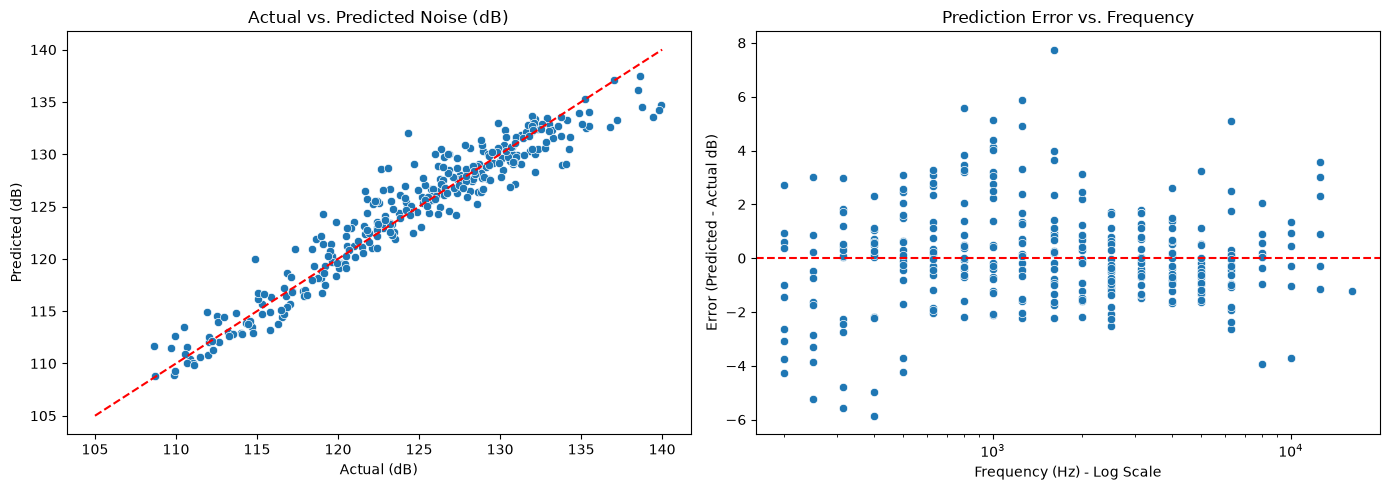

In [28]:
# Fit Tuned CatBoost inside a Pipeline and predict on test
best_pipe = Pipeline(
    [("model", CatBoostRegressor(**study_cb.best_params, random_seed=42, verbose=0))]
)
best_pipe.fit(x_train, y_train)

# Calculate prediction errors on test
err_df = test.copy()
err_df["pred_db"] = best_pipe.predict(x_test)
err_df["error_db"] = err_df["pred_db"] - err_df["scaled_sound_pressure_level_db"]
err_df["abs_error_db"] = err_df["error_db"].abs()

# Print Top 10 Worst Cases
print("Top 10 Worst Predictions (Test Set):")
print(err_df.sort_values("abs_error_db", ascending=False).head(10).round(2))

# Print Average Error per Test Configuration
print("\nAverage Error by Blade Configuration:")
cfg_err = err_df.groupby("config_id")["abs_error_db"].agg(["count", "mean", "max"]).sort_values("mean", ascending=False)
print(cfg_err.round(2))

# Plot Two Simple Error Figures
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Actual vs. Predicted
sns.scatterplot(data=err_df, x="scaled_sound_pressure_level_db", y="pred_db", ax=axes[0])
axes[0].plot([105, 140], [105, 140], "r--")
axes[0].set_title("Actual vs. Predicted Noise (dB)")
axes[0].set_xlabel("Actual (dB)")
axes[0].set_ylabel("Predicted (dB)")

# Plot 2: Error vs. Frequency
sns.scatterplot(data=err_df, x="frequency_hz", y="error_db", ax=axes[1])
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xscale("log")
axes[1].set_title("Prediction Error vs. Frequency")
axes[1].set_xlabel("Frequency (Hz) - Log Scale")
axes[1].set_ylabel("Error (Predicted - Actual dB)")

plt.tight_layout()
plt.show()

1. Top 10 Worst Predictions Table<br>

The Single Worst Case (config_id 47, Row 777): At 1600 Hz, 4.2° angle, 0.05 m chord, and 71.3 m/s speed, actual noise was 124.32 dB, but CatBoost predicted 132.07 dB (+7.75 dB error). In our EDA, we saw 4.2° was one of the rarest tilt angles in the training set (only ~10 rows), so the model had very little data near that exact angle.

Repeated Trouble on config_id 67 (Rows 391, 392, 393): Three of the top ten errors come from the exact same blade setup (7.3° angle, 0.23 m chord, 71.3 m/s speed) at low frequencies (250, 315, 400 Hz). This blade produced nearly 140 dB at low frequencies, and CatBoost under-predicted all three by 5.2 to 5.9 dB.

High Air Speed Dominates Worst Errors: 7 out of the 10 worst errors happen at the maximum air speed of 71.3 m/s, where airflow turbulence is strongest and hardest to predict.

2. Average Error by Blade Configuration Table<br>

Out of 22 test configurations, 16 configurations have a very low average error below 1.55 dB (and the best ones, config_id 10 and 33, are under 0.50 dB).

config_id 100, 67, 97, 81 have an average error above 2.1 dB (2.13 to 2.65 dB). All four involve steep angles (9.9° to 17.4°) or large blades at high speed (0.23 m at 71.3 m/s), the exact location where training examples were sparse.

3. Actual vs. Predicted Noise Plot (Left Figure)<br>

Almost all blue dots cluster tightly along the red dashed line from 108 dB to 135 dB. This shows CatBoost predicts typical blade noise very accurately.   

At the far top-right corner (actual noise near 138–140 dB), the dots sit below the red dashed line (predicted around 134–137 dB). When a blade creates extreme noise above 138 dB, the model underestimates how loud it is by about 4 to 6 dB.   

4. Prediction Error vs. Frequency Plot (Right Figure)<br>

Most dots sit within ±2 dB of the red zero line across the middle frequencies (2,000 Hz to 5,000 Hz), where most training data sits.

Where Large Mistakes Happen: 
- Low Frequencies (250–400 Hz): Errors drop down to -5.86 dB (the model guesses too low)
- Lower-Middle Frequencies (800–1,600 Hz): Errors spike up to +7.75 dB (the model guesses too high).

# Recommendation to Engineering Team

### What the Model Can Do: 

On unseen blade setups, the tuned CatBoost surrogate predicts sound levels within 1.40 dB to 1.93 dB on average (Test MAE: 1.40 dB, CV MAE: 1.93 dB).

Across different validation splits, the root mean squared error is 2.76 ± 0.32 dB (and 1.90 dB on the held-out test set). For most standard designs, predictions stay within ±2.0 dB of physical wind-tunnel measurements.   

Best Use Case: Use this model as a fast early-stage screening tool to compare candidate blade sizes, speeds, and tilt angles also to filter out clearly noisy designs before booking expensive wind-tunnel time.

### When NOT to Trust the Surrogate (Blind Spots & Limitations)

1. Outside Tested Input Ranges (Extrapolation):  

The model was only trained on NACA 0012 airfoils within fixed limits:
- Frequency: 200 Hz to 20,000 Hz
- Angle of Attack: 0° to 22.2°  
- Chord Length: 0.0254 m to 0.3048 m   
- Air Speed: 31.7 m/s to 71.3 m/s

Tree models cannot extrapolate beyond these boundaries.   

2. Untested Feature Combinations (Coverage Gaps):

Large Blades at Steep Angles: Blades wider than 0.20 m were only tested at gentle angles up to 7.3°. Never trust predictions for a wide blade tilted above 8°.  

Steep Angles at Medium/Low Air Speeds: Angles above 17.4° were only tested at 39.6 m/s and 71.3 m/s. Predictions at 31.7 m/s or 55.5 m/s for steep angles sit in empty data gaps.   

3. High-Error Operating Zones:

Maximum Air Speed (71.3 m/s) & Low Frequencies (< 500 Hz): Error analysis showed the model can underestimate loud low-frequency noise by 5 to 6 dB (for example, predicting 134 dB when actual noise was 140 dB).

Extreme Loudness (> 138 dB): The model tends to under-predict peak loudness above 138 dB by 4 to 6 dB, so do not use it to verify strict upper noise limits. 

Different Blade Shapes or Real-World Field Conditions: The training data comes from clean, controlled anechoic wind-tunnel tests. Do not use this model for non-NACA 0012 blade profiles, damaged/iced surfaces, serrated trailing edges, or turbulent outdoor environments.

### Practical Recommendation for Engineering Team
1. Test on Computer First. Use the CatBoost model to quickly check hundreds of blade ideas and remove the noisy ones. Then, only spend money testing the top 5 to 10 quietest designs in the real wind tunnel.
2. Add a 3 dB Safety Buffer. Because the model can be off by a few decibels, always add +3 dB to the model's noise guess when checking against a strict noise limit. This ensures borderline noisy blades do not pass by mistake.
3. Set Up Automatic Warning Flags. Program the tool to show a warning whenever an engineer enters numbers the model has never seen, such as speeds outside 31.7–71.3 m/s, or a wide blade (> 0.15 m) combined with a steep tilt (> 8°).  
4. Run New Wind-Tunnel Tests in Empty Zones. If the team needs to design wide blades at steep angles (10°–20°) or test medium air speeds (45–65 m/s), run a few real wind-tunnel tests in those missing areas and update the model so it learns those patterns.